# Large Scale Singular Value Decomposition Tracking Demonstration

This notebook demonstrates the tracking of Singular Value Decomposition (SVD) for a large parameter-dependent matrix $A(t)$. We follow the structure of the eigenpair tracking demo, linearly interpolating between two random matrices.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import time
from eigenpairflow.tracking import singularpairtrack

plt.style.use('seaborn-v0_8-whitegrid')

## Problem Setup

We construct a matrix path $A(t)$ of size $20 \times 20$ by linearly interpolating two random matrices $A_0$ and $A_1$.

$$ A(t) = (1-t)A_0 + t A_1 $$

In [2]:
n = 12
t_eval = np.linspace(0.0, 1.0, 500)

np.random.seed(0)

def rand_near_orthogonal_cayley(Q0, eps=6.0e-3):
    n = Q0.shape[0]
    U = np.triu(np.random.randn(n, n), 1)
    S = eps * (U - U.T)
    R = np.linalg.solve(np.eye(n) - S, np.eye(n) + S)   # (I-S)^{-1}(I+S)
    return Q0 @ R

# perturb the rotation to induce both curve crossing and curve veering
Q0, _ = np.linalg.qr(np.random.randn(n, n))
Q1 = rand_near_orthogonal_cayley(Q0)

# flip eigenvalues to create crossings
eigvals0 = np.random.uniform(0, 1, n)
eigvals1 = eigvals0[::-1]

A0 = Q0 @ np.diag(eigvals0) @ Q0.T
A1 = Q1 @ np.diag(eigvals1) @ Q1.T

def A_func(t):
    """Return the interpolated symmetric matrix A(t)."""
    return (1 - t) * A0 + t * A1

## SVD Tracking (Ogita's Iterative Refinement)

We use `singularpairtrack` which employs Ogita's iterative algorithm to continuously update the SVD.

In [3]:
start = time()
results = singularpairtrack(
    A_func,
    t_eval,
    tol=1e-10
)
elapsed = time() - start

print('Ogita SVD Tracking')
print('=' * 20)
print(f'Time: {elapsed:.4f} secs')
print(f'Success: {results.success}')
print(f'Message: {results.message}')

Ogita SVD Tracking
Time: 0.4570 secs
Success: True
Message: Ogita-SVD Tracking


## Tracked Singular Values

Visualizing a subset of the singular values over time.

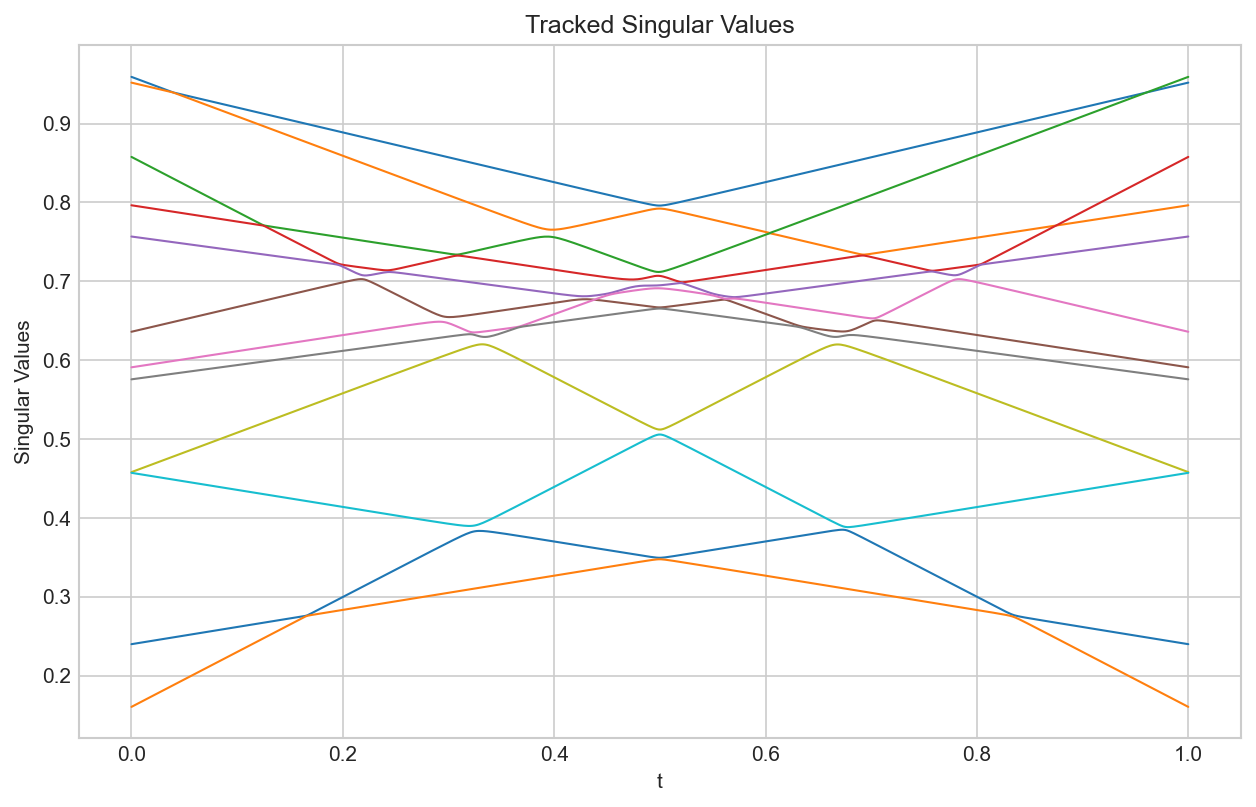

In [4]:
plt.figure(figsize=(10, 6), dpi=150)
singular_vals = np.array(results.Ss)
plt.plot(t_eval, singular_vals, lw=1)
plt.title(f'Tracked Singular Values')
plt.xlabel('t')
plt.ylabel('Singular Values')
plt.show()

## Reconstruction Error

Checking the Frobenius norm error $||A(t) - U(t) \Sigma(t) V(t)^T||_F$. 

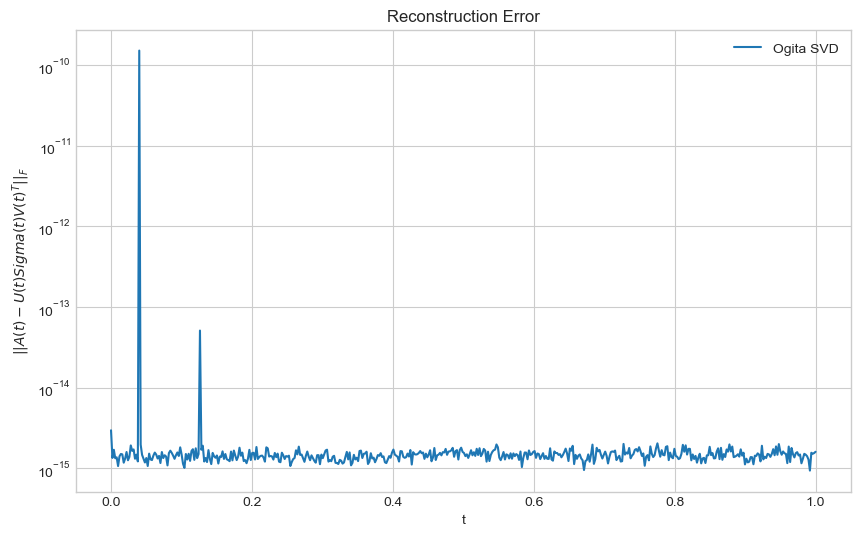

Total accumulated error: 1.5150e-10


In [5]:
plt.figure(figsize=(10, 6))
plt.plot(t_eval, results.norm_errors, label='Ogita SVD')
plt.yscale('log')
plt.xlabel('t')
plt.ylabel(r'$||A(t) - U(t) Sigma(t) V(t)^T||_F$')
plt.title('Reconstruction Error')
plt.legend()
plt.show()

print(f'Total accumulated error: {np.sum(results.norm_errors):.4e}')